In [1]:
import pandas as pd
import numpy as np
import os

In [2]:
table = pd.read_csv("examples/pre10_genus.tsv", sep='\t', index_col=0)
meta = pd.read_csv("examples/final_italy_mmi.tsv", sep='\t').set_index("#SampleID")

## Example

In [3]:
meta = meta[meta["Host_disease"] == "Control"].copy()

table = table.loc[meta.index]

In [4]:
table.head(3)

,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Rikenellaceae;g__Alistipes_A_871400,d__Bacteria;p__Pseudomonadota;c__Gammaproteobacteria;o__Enterobacterales_737866;f__Enterobacteriaceae_A_725029;g__Escherichia,d__Bacteria;p__Actinomycetota;c__Coriobacteriia;o__Coriobacteriales;f__Atopobiaceae;g__Lancefieldella,d__Bacteria;p__Bacillota_A_368345;c__Clostridia_258483;o__Peptostreptococcales;f__Anaerovoracaceae;g__Eubacterium_B,d__Bacteria;p__Bacillota_A_368345;c__Clostridia_258483;o__Oscillospirales;f__Butyricicoccaceae;g__Agathobaculum,d__Bacteria;p__Bacillota_A_368345;c__Clostridia_258483;o__Lachnospirales;f__Lachnospiraceae;__,d__Bacteria;p__Pseudomonadota;c__Gammaproteobacteria;o__Burkholderiales;f__Burkholderiaceae_A_595427;g__Sutterella,d__Bacteria;p__Bacillota_A_368345;c__Clostridia_258483;o__Oscillospirales;f__Ruminococcaceae;g__Gemmiger_A_73129,d__Archaea;p__Methanobacteriota_A_1229;c__Methanobacteria;o__Methanobacteriales;f__Methanobacteriaceae;g__Methanobrevibacter_A,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Bacteroidaceae;g__Bacteroides_H_857956,...,d__Bacteria;p__Bacillota_A_368345;c__Clostridia_258483;o__Oscillospirales;f__Oscillospiraceae_88309;g__Onthomonas,d__Bacteria;p__Bacillota_A_368345;c__Clostridia_258483;o__Oscillospirales;f__Oscillospiraceae_88309;g__Evtepia,d__Bacteria;p__Actinomycetota;c__Coriobacteriia;o__Coriobacteriales;f__Eggerthellaceae;g__Anaerotardibacter,d__Bacteria;p__Bacillota_A_368345;c__Clostridia_258483;o__Oscillospirales;f__Ruminococcaceae;g__Merdimmobilis,d__Bacteria;p__Actinomycetota;c__Coriobacteriia;o__Coriobacteriales;f__Eggerthellaceae;g__Gordonibacter,d__Bacteria;p__Pseudomonadota;c__Gammaproteobacteria;o__Burkholderiales;f__Burkholderiaceae_A_595421;g__Oxalobacter,d__Bacteria;p__Bacillota_A_368345;c__Clostridia_258483;o__Oscillospirales;f__Ruminococcaceae;g__Negativibacillus,d__Bacteria;p__Bacillota_A_368345;c__Clostridia_258483;o__Oscillospirales;f__Acutalibacteraceae;g__Solibaculum,d__Bacteria;p__Bacillota_A_368345;c__Clostridia_258483;o__Oscillospirales;f__Acutalibacteraceae;g__UMGS1071,d__Bacteria;p__Bacillota_A_368345;c__Clostridia_258483;o__Monoglobales;f__Monoglobaceae;g__Monoglobus
#SampleID,,,,,,,,,,,,,,,,,,,,,
SRR23478195,0.0,107.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
SRR23478196,0.0,291.0,0.0,0.0,0.0,108.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0
SRR23478197,0.0,28.0,8.0,0.0,0.0,0.0,0.0,0.0,0.0,384.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,0.0


In [5]:
meta.head(3)

,Unnamed: 0,real_age,mmi,real_year,pred_year,Months,host_sex,Host_disease,location_disease,mean_age,Separation,Network,Group
#SampleID,,,,,,,,,,,,,
SRR23478195,0,18.0,69.95,1.0,5.33,18.0,female,Control,Control(IT),50.04,mmihigh,mmihigh,mmihigh
SRR23478196,1,18.0,42.65,1.0,3.05,18.0,male,Control,Control(IT),50.04,mmilow,mmilow,mmilow
SRR23478197,2,18.0,37.51,1.0,2.63,18.0,female,Control,Control(IT),50.04,mmilow,mmilow,mmilow


In [6]:
from ancombc_viz.simple_name import extract_species
from ancombc_viz.simple_name import extract_p_g_or_f
from ancombc_viz.ancombc import Analyzer
from ancombc_viz.plotting import plot_group_bar

In [7]:
# top30_short_names = {
#     col: extract_p_g_or_f(col)
#     for col in table.columns1
# } ## Genus

top30_short_names = {
    col: extract_species(col)
    for col in table.columns
} ## Species

anc = Analyzer()
anc.set_feature_table(table)
anc.set_metadata(meta, formula="Group")
sig = anc.ancombc_analysis(feature_name_map=top30_short_names)
## ana = Analyzer()
## ana.set_feature_table(ft)
## ana.set_metadata(mt)
## sig = ana.ancombc_analysis()

sig


/home/pss8993/repo/ancombcviz/ancombc_viz/ancombc.py:34: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  self.ancombc_signif = (self.results.query('Covariate != "Intercept" & Signif == True').round(3).reset_index().copy())


,FeatureID,Covariate,Log2(FC),SE,W,pvalue,qvalue,Signif
0,p__Bacillota_A_368345;g__Eubacterium_G_180878,Group[T.mmilow],-0.927,0.247,-3.754,0.0,0.032,True
1,p__Bacillota_A_368345;g__Ruminococcus_B,Group[T.mmilow],1.420,0.372,3.815,0.0,0.025,True
2,p__Actinomycetota;g__Eggerthella,Group[T.mmilow],1.987,0.371,5.361,0.0,0.000,True
3,p__Bacillota_A_368345;g__Hominicoprocola,Group[T.mmilow],-1.442,0.319,-4.525,0.0,0.001,True
4,p__Bacillota_A_368345,Group[T.mmilow],-0.661,0.137,-4.821,0.0,0.000,True
5,p__Bacillota_A_368345;g__Lawsonibacter,Group[T.mmilow],-0.763,0.204,-3.736,0.0,0.034,True
6,p__Bacillota_A_368345;g__Dysosmobacter,Group[T.mmilow],-1.102,0.293,-3.765,0.0,0.031,True
7,p__Bacteroidota;g__Alistipes_A_871404,Group[T.mmilow],-1.487,0.255,-5.839,0.0,0.000,True
8,p__Bacillota_A_368345;g__Anaerotruncus,Group[T.mmilow],-0.615,0.162,-3.797,0.0,0.027,True
9,p__Bacillota_A_368345;g__Terrisporobacter,Group[T.mmilow],1.163,0.297,3.916,0.0,0.017,True


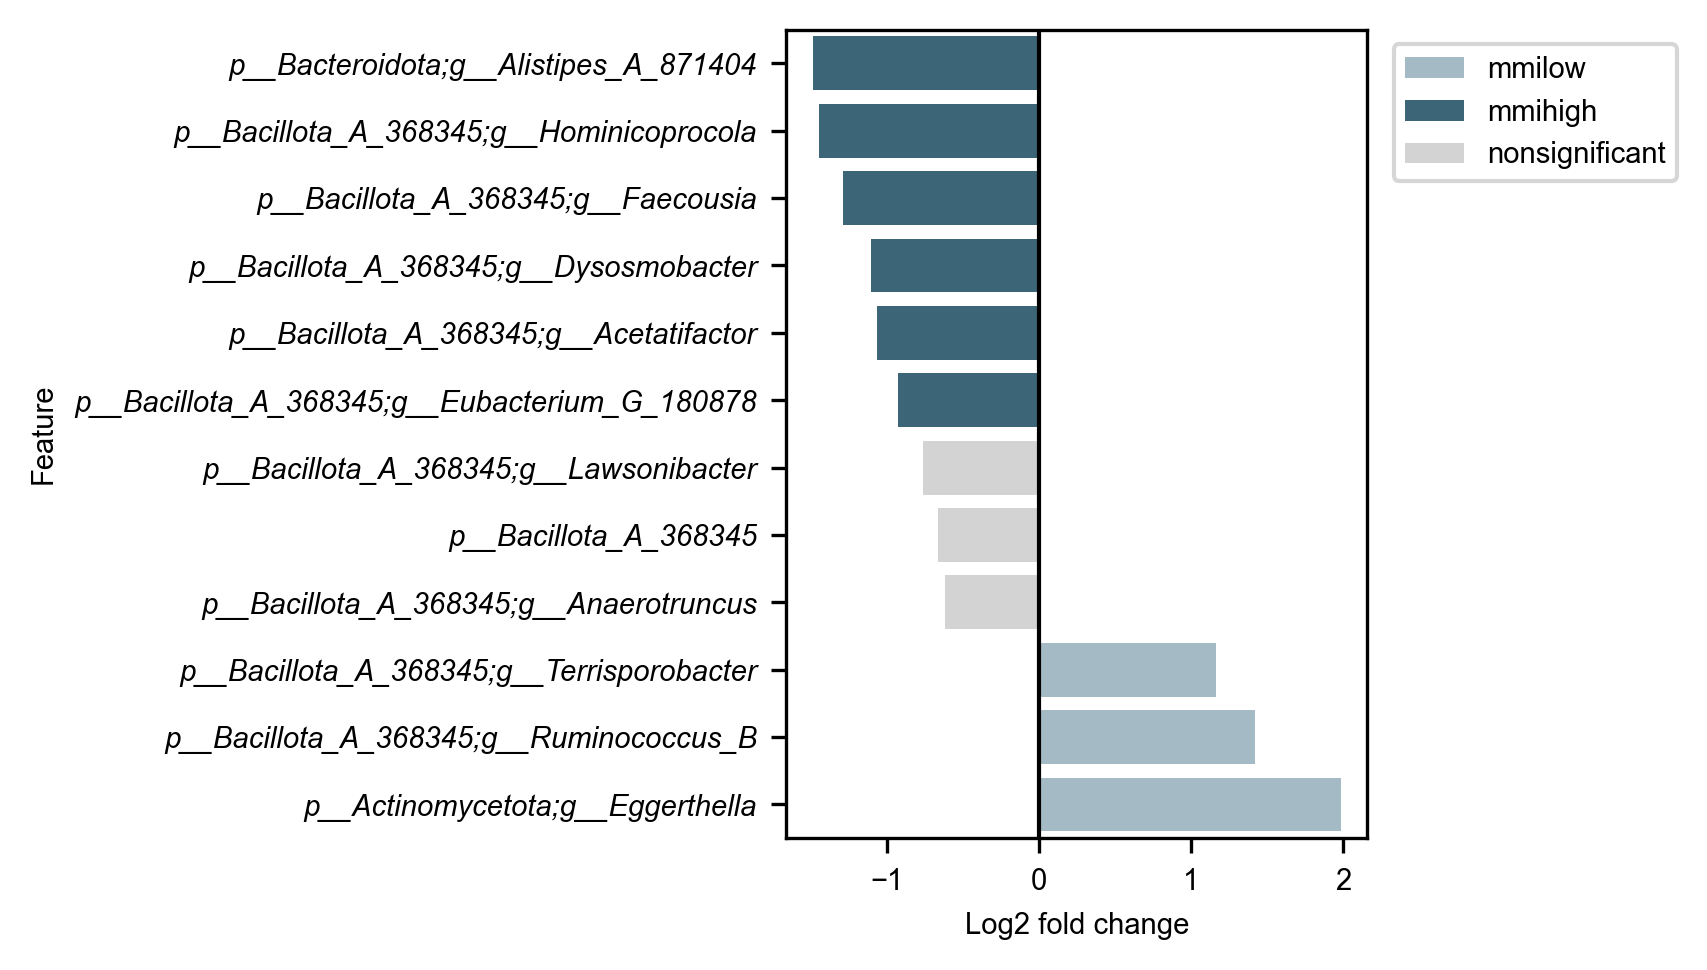

In [8]:
plot_group_bar(sig, group="mmilow", ref_group="mmihigh", top_n=30, fc_cut = 0.9, top_name_map=None, ax=None, save_path="examples/example.pdf")